In [ ]:
from mirtorch.linear import Identity, Diff3dgram, NuSense, NuSenseGram
from mirtorch.alg import CG, power_iter, POGM
from mirtorch.prox import Const, L1Regularizer
import torch
from obj.RawData import *
from obj.helpers import *
import numpy as np
import matplotlib.pyplot as plt
from obj.FSLViewer import FSLViewer
from obj.Smap import Smaps
import gc
from obj.pblms import *

In [2]:
def dsize(x):
    return (x.numel() * x.element_size()) / (1024 ** 3)

def p_dsize(x):
    print(dsize(x), " GiB")

In [ ]:
viewer = FSLViewer()

device = best_available_device()
torch.manual_seed(0)
print(f"Using {device}")

smap = Smaps.load("/home/clouly/DEV/asldata/20260731/smaps/grey_64_smap.mat", cdim=-1, dtype=torch.complex64, device=device).compress(4)
viewer.add_smap(smap)
print(smap)

Using cuda
<Smaps Object: On cuda:0 with shape (8, 64, 64, 64). Currently COMPRESSED>


In [ ]:
y_itr = RawData.from_glob("/home/clouly/DEV/asldata/20260731/asldata_look*000*", verbose=True).__iter__()
y_raw = y_itr.__next__().to(device)
print("PRE SHAPING")
print(y_raw)
print(y_raw.data.shape)
print(y_raw.traj.shape)

Working on '/home/clouly/DEV/asldata/20260731/asldata_looklocker_pld0000':
PRE SHAPING
<RawData Object: On cuda:0 with shape (3331, 50, 100, 32)>
torch.Size([3331, 50, 100, 32])
torch.Size([3331, 50, 100, 3])


In [5]:
ws = 5

y_raw = y_raw.initial_clip().coil_compress(smap).to("cpu").capria_swap().window(5, 2, 0)

bs = y_raw.data.shape[2]

In [6]:
yl_raw, yc_raw = y_raw.split_cl(dim=1)
print(yl_raw, yc_raw)

<RawData Object: On cpu with shape (16405, 50, 46, 8)> <RawData Object: On cpu with shape (16405, 50, 46, 8)>


In [7]:
yl_raw = yl_raw.set_mirt_shape()
yc_raw = yc_raw.set_mirt_shape()


In [8]:
ktraj = yl_raw.traj.to("cpu")
yl = yl_raw.data.to("cpu")
yc = yc_raw.data.to("cpu")

yl_raw = yl_raw.to("cpu")
yc_raw = yc_raw.to("cpu")

In [9]:
p_dsize(ktraj)

0.42168237268924713  GiB


In [10]:
vt = list(ktraj.shape)
vt[1] = 1

w = torch.full(tuple(vt), 1.0, dtype=torch.complex64, device=device)
fake_smap = torch.full(smap.shape[1:], 1.0, dtype=torch.complex64, device=device)[None, None, ...]
Af = NuSense(fake_smap, ktraj.to(device)).to(device)

w, sn = power_iter(Af * Af.H, w, max_iter=10)
w = torch.real(w)
w /= torch.linalg.norm(w)

w = w.to("cpu")
p_dsize(w)
del Af
del fake_smap

gc.collect()
torch.cuda.empty_cache()

0.1405607908964157  GiB


In [11]:
gc.collect()
torch.cuda.empty_cache()

In [12]:
def hns(v):
    return 0.5 * (torch.linalg.norm(v).item() ** 2)

In [13]:
def init_scale(A, y, x0):
    # Find argmin_s 1/2 ||y - s A x0||_2^2
    Ax0 = A * x0
    return x0 * torch.sum(y.conj() * Ax0).conj() / (2 * hns(Ax0))

In [14]:
do_pogm = False
max_iter=500
cl_reg = 10**0
s_reg = 10**-1
m_reg = 10**-4

In [15]:
print(smap[None].shape)

torch.Size([1, 8, 64, 64, 64])


In [ ]:
A = PBNuSense(smap[None].get_tensor().to("cpu"), ktraj, batchsize=bs).to("cpu").to(device)
AhA = PBNuSenseGram(smap[None].get_tensor().to("cpu"), ktraj, batchsize=1).to("cpu").to(device)
R = Identity(A.size_in).to(device)

print(A.H.size_in, A.H.size_out)
print(AhA.size_in, AhA.size_out)

[46, 8, 820250] [46, 1, 64, 64, 64]
[46, 1, 64, 64, 64] [46, 1, 64, 64, 64]


In [19]:
gc.collect()
torch.cuda.empty_cache()

### Label Recon


In [20]:
print("RECONNING --- LABEL")
y = yl
y_nrm = torch.linalg.norm(y).item()

AHy = A.H * y.to(device)
AHyw = A.H * (y.to(device) * w.to(device))

gc.collect()
torch.cuda.empty_cache()

s = torch.real(torch.sum(AHyw * AHy.conj(), dim=tuple(range(1, AHy.ndim))))
s = s / torch.real(torch.sum(torch.abs(A * AHyw) ** 2, dim=tuple(range(1, len(A.size_out)))))
x0 = AHyw * s[:, None, None, None, None]

del AHyw
gc.collect()
torch.cuda.empty_cache()

if not do_pogm:
    xl, recon_time = timed(
        lambda: CG(
            AhA + cl_reg * R,
            alert=True,
            max_iter=max_iter,
            eval_func= lambda res: (torch.linalg.norm(res)).item()
        ).run(x0, AHy, return_info=True),
        device
    )
else:
    xl, recon_time = timed(
        lambda: POGM(
            f_grad= lambda x: ((A.H * A) * x) - (A.H * y) + cl_reg * x,
            f_L= sn + cl_reg,
            g_prox= Const(),
            max_iter=max_iter,
            eval_func= lambda x: (hns(A * x - y) + cl_reg * hns(x)),
            rtol=10**-4
        ).run(x0, return_info=True),
        device
    )

print("Recon Took:", recon_time)
print(torch.linalg.norm(AHy) ** 2)

RECONNING --- LABEL
Recon Took: 42.30287211947143
tensor(1.4150e+17, device='cuda:0')


Recon Took: 42.30287211947143
Label     True 122 0.0975874811410904


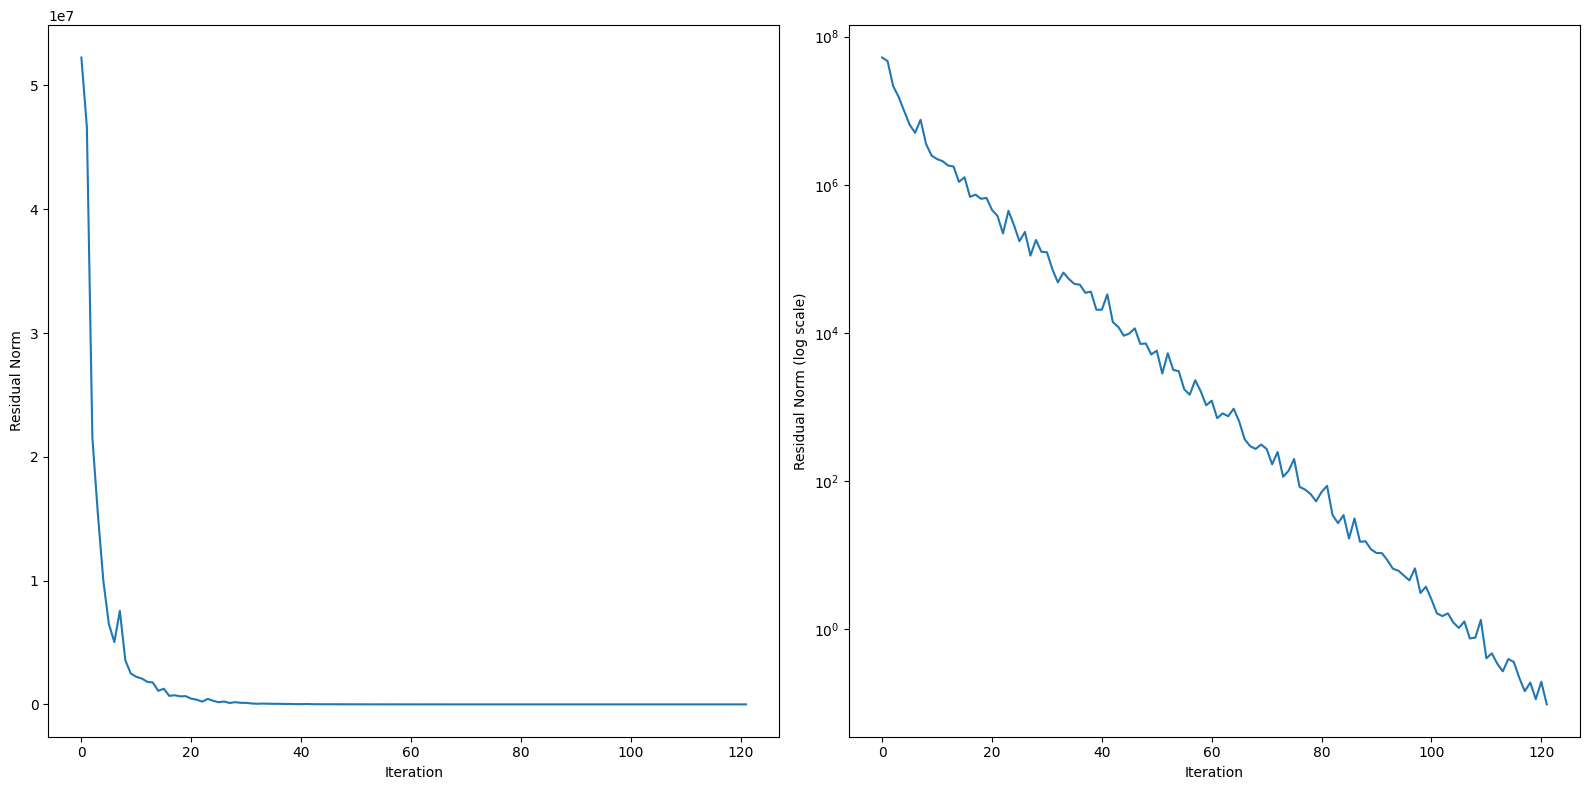

In [21]:
xl_img = xl.solution.squeeze(1)
viewer.add(torch.angle(xl_img), "label_img_ang", tdim=0)
viewer.add(torch.abs(xl_img), "label_img_mag", tdim=0)
print("Recon Took:", recon_time)
print("Label    ", xl.converged, xl.iterations, xl.residual_norm.item())

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 8))

#for c in xl_res: ax[0].plot(c)
ax[0].plot(xl.history)
ax[0].set_xlabel("Iteration")
ax[0].set_ylabel("Residual Norm")

#for c in xl_res: ax[1].semilogy(c)
ax[1].semilogy(xl.history)
ax[1].set_xlabel("Iteration")
ax[1].set_ylabel("Residual Norm (log scale)")

fig.tight_layout()
plt.show()

In [26]:
A = A.to("cpu")
AhA = AhA.to("cpu")
R = R.to("cpu")

gc.collect()
torch.cuda.empty_cache()

A = A.to(device)
AhA = AhA.to(device)
R = R.to(device)

### Control Recon

In [27]:
print("RECONNING --- CONTROL")
y = yc
y_nrm = torch.linalg.norm(y).item()

AHy = A.H * y.to(device)
AHyw = A.H * (y.to(device) * w.to(device))

gc.collect()
torch.cuda.empty_cache()

s = torch.real(torch.sum(AHyw * AHy.conj(), dim=tuple(range(1, AHy.ndim))))
#s = s / torch.real(torch.sum(torch.abs(A * AHyw) ** 2, dim=tuple(range(1, len(A.size_out)))))
s = s / torch.real(torch.sum(AHyw.conj() * (AhA * AHyw), dim=tuple(range(1, AHyw.ndim))))
x0 = AHyw * s[:, None, None, None, None]

del AHyw
gc.collect()
torch.cuda.empty_cache()

if not do_pogm:
    xc, recon_time = timed(
        lambda: CG(
            AhA + cl_reg * R,
            alert=True,
            max_iter=max_iter,
            eval_func= lambda res: (torch.linalg.norm(res)).item()
        ).run(x0, AHy, return_info=True),
        device
    )
else:
    xc, recon_time = timed(
        lambda: POGM(
            f_grad= lambda x: ((A.H * A) * x) - (A.H * y) + cl_reg * x,
            f_L= sn + cl_reg,
            g_prox= Const(),
            max_iter=max_iter,
            eval_func= lambda x: (hns(A * x - y) + cl_reg * hns(x)),
            rtol=10**-4
        ).run(x0, return_info=True),
        device
    )

print("Recon Took:", recon_time)
print(torch.linalg.norm(AHy) ** 2)

RECONNING --- CONTROL
Recon Took: 42.72595475614071
tensor(1.4059e+17, device='cuda:0')


Recon Took:  42.72595475614071
Control:     True 122 0.09931083768606186


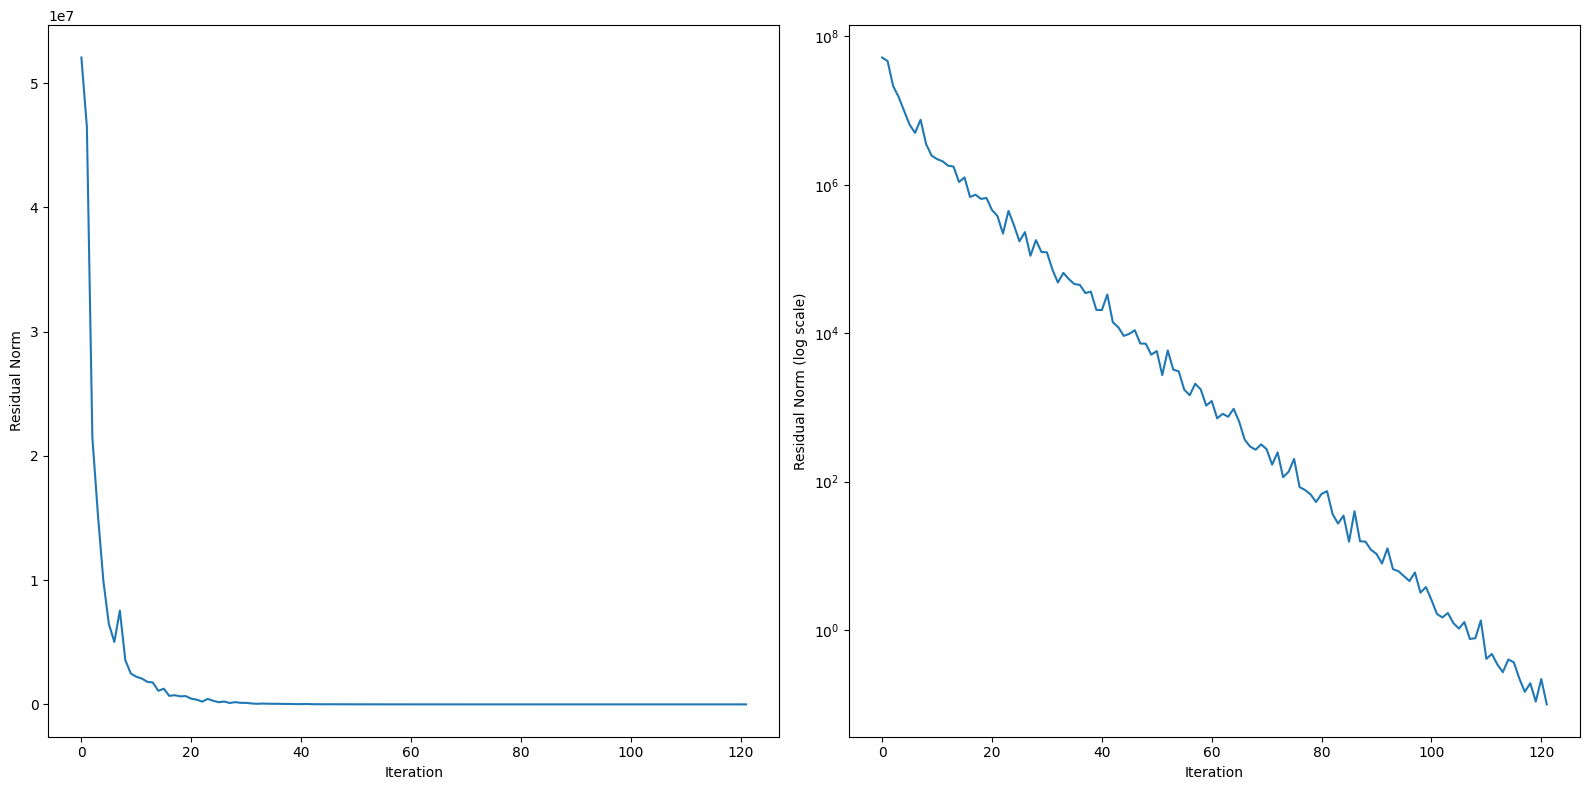

In [28]:
xc_img = xc.solution.squeeze(1)
viewer.add(torch.angle(xc_img), "control_img_ang", tdim=0)
viewer.add(torch.abs(xc_img), "control_img_mag", tdim=0)
print("Recon Took: ", recon_time)
print("Control:    ", xc.converged, xc.iterations, xc.residual_norm.item())

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 8))

ax[0].plot(xc.history)
ax[0].set_xlabel("Iteration")
ax[0].set_ylabel("Residual Norm")

ax[1].semilogy(xc.history)
ax[1].set_xlabel("Iteration")
ax[1].set_ylabel("Residual Norm (log scale)")

fig.tight_layout()
plt.show()

In [29]:
viewer.add(torch.angle(xl_img - xc_img), "imspace_sub_img_ang", tdim=0)
viewer.add(torch.abs(xl_img - xc_img), "imspace_sub_img_mag", tdim=0)
viewer.add(torch.angle((xl_img + xc_img).mean(dim=0)), "imspace_mean_img_ang")
viewer.add(torch.abs((xl_img + xc_img).mean(dim=0)), "imspace_mean_img_mag")

In [35]:
A = A.to("cpu")
AhA = AhA.to("cpu")
R = R.to("cpu")

gc.collect()
torch.cuda.empty_cache()

A = A.to(device)
AhA = AhA.to(device)
R = R.to(device)

### Subtraction Recon

In [31]:
from mirtorch.alg import FISTA

In [36]:
print("RECONNING --- SUBTRACTION")
y = yl - yc
y_nrm = torch.linalg.norm(y).item()

AHy = A.H * y.to(device)
AHyw = A.H * (y.to(device) * w.to(device))

gc.collect()
torch.cuda.empty_cache()

s = torch.real(torch.sum(AHyw * AHy.conj(), dim=tuple(range(1, AHy.ndim))))
s = s / torch.real(torch.sum(AHyw.conj() * (AhA * AHyw), dim=tuple(range(1, AHyw.ndim))))
x0 = AHyw * s[:, None, None, None, None]

del AHyw
gc.collect()
torch.cuda.empty_cache()

AHym= AHy.to(device)
x0 = x0.to(device)
y = y.to(device)

if not True:
    xs, recon_time = timed(
        lambda: CG(
            (A.H * A) + s_reg * R,
            alert=True,
            max_iter=max_iter,
            eval_func= lambda res: (torch.linalg.norm(res)).item()
        ).run(x0, AHy, return_info=True),
        device
    )
else:
    xs, recon_time = timed(
        lambda: FISTA(
            f_grad= lambda x: AhA * x - AHy,
            f_L= sn.to(device),
            g_prox= L1Regularizer(s_reg*100),
            max_iter=max_iter,
            eval_func= lambda x: (hns(x - AHy)),
            rtol= (10 ** -6)
        ).run(x0, return_info=True),
        device
    )

print("Recon Took:", recon_time)
print(torch.linalg.norm(AHy) ** 2)

RECONNING --- SUBTRACTION
Recon Took: 180.95143627375364
tensor(8.5589e+13, device='cuda:0')


Recon Took:  180.95143627375364
Sub:         False 500 194.46646118164062


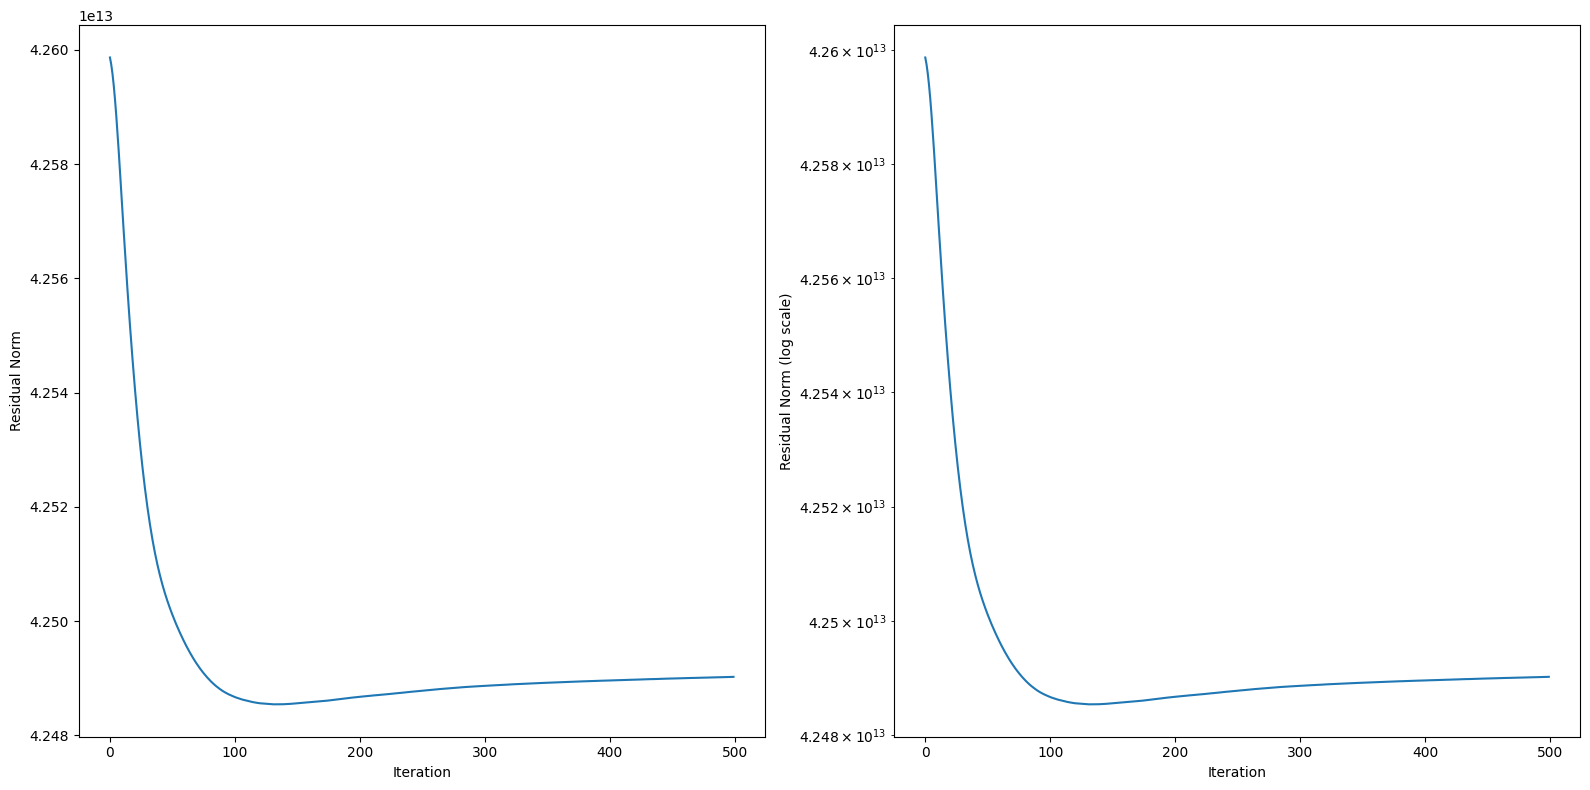

In [37]:
xs_img = xs.solution.squeeze(1)
viewer.add(torch.angle(xs_img), "subtraction_img_ang", tdim=0)
viewer.add(torch.abs(xs_img), "subtraction_img_mag", tdim=0)
print("Recon Took: ", recon_time)
print("Sub:        ", xs.converged, xs.iterations, xs.residual_norm.item())

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 8))

ax[0].plot(xs.history)
ax[0].set_xlabel("Iteration")
ax[0].set_ylabel("Residual Norm")

ax[1].semilogy(xs.history)
ax[1].set_xlabel("Iteration")
ax[1].set_ylabel("Residual Norm (log scale)")

fig.tight_layout()
plt.show()

In [34]:
assert False

AssertionError: 

### Mean Reconstruction

In [ ]:
print("RECONNING")
y = (yl.data + yc.data)
y_nrm = torch.linalg.norm(y).item()

AHy = A.H * y
x0 = init_scale(A, y, A.H * (y * w))

if not do_pogm:
    xm, recon_time = timed(
        lambda: CG(
            (A.H * A) + m_reg * R,
            alert=True,
            max_iter=max_iter,
            eval_func= lambda res: (torch.linalg.norm(res)).item()
        ).run(x0, AHy, return_info=True),
        device
    )
else:
    xm, recon_time = timed(
        lambda: POGM(
            f_grad= lambda x: ((A.H * A) * x) - (A.H * y) + m_reg * x,
            f_L= sn + m_reg,
            g_prox= Const(),
            max_iter=max_iter,
            eval_func= lambda x: (hns(A * x - y) + m_reg * hns(x)),
            rtol=10**-4
        ).run(x0, return_info=True),
        device
    )

print("Recon Took:", recon_time)
print(torch.linalg.norm(AHy) ** 2)

RECONNING
Recon Took: 54.77429180871695
tensor(2.7131e+16, device='cuda:0')


Recon Took:  54.77429180871695
Mean:        False 20 638763.375


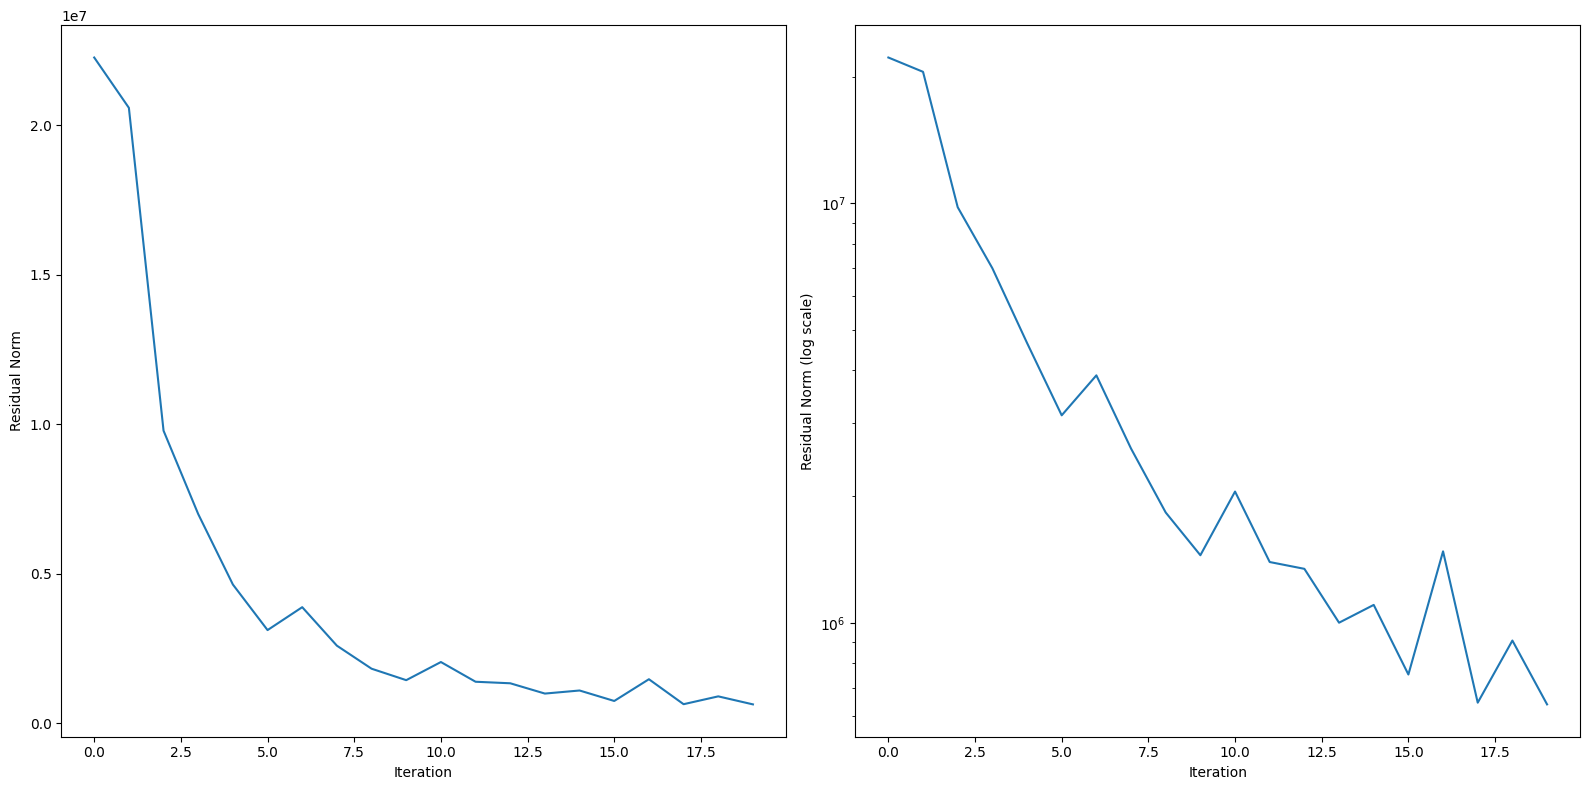

In [ ]:
xm_img = xm.solution.squeeze(1).mean(dim=0)
viewer.add(torch.angle(xm_img), "mean_img_ang")
viewer.add(torch.abs(xm_img), "mean_img_mag")
print("Recon Took: ", recon_time)
print("Mean:       ", xm.converged, xm.iterations, xm.residual_norm.item())

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 8))

ax[0].plot(xm.history)
ax[0].set_xlabel("Iteration")
ax[0].set_ylabel("Residual Norm")

ax[1].semilogy(xm.history)
ax[1].set_xlabel("Iteration")
ax[1].set_ylabel("Residual Norm (log scale)")

fig.tight_layout()
plt.show()

In [ ]:
viewer.add(torch.angle(xl_img - xc_img), "imspace_sub_img_ang", tdim=0)
viewer.add(torch.abs(xl_img - xc_img), "imspace_sub_img_mag", tdim=0)

In [ ]:
viewer.add(torch.abs((xl_img + xc_img).mean(dim=0)), "imspace_mean_img_mag")

In [ ]:
assert False

AssertionError: 

In [ ]:
viewer.close()